# Predicting Cancellations with Machine Learning

In [1]:
import pandas as pd

df = pd.read_csv("../data/hotel_bookings_clean.csv")

numeric_features = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "days_in_waiting_list", "adr", "total_of_special_requests", "total_nights", "total_guests",
]
categorical_features = [
    "hotel", "arrival_date_month", "meal", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type", "customer_type",
]

X = df[numeric_features + categorical_features]
y = df["is_canceled"]
print("Features:", X.shape[1], "| Bookings:", len(y))

Features: 24 | Bookings: 119208


In [2]:
X = pd.get_dummies(X, columns=categorical_features)
print("Columns after encoding:", X.shape[1])
X[["hotel_City Hotel", "hotel_Resort Hotel"]].head(3)

Columns after encoding: 64


,hotel_City Hotel,hotel_Resort Hotel
0,False,True
1,False,True
2,False,True


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))
print("Cancel rate in train:", round(y_train.mean() * 100, 1), "%")
print("Cancel rate in test: ", round(y_test.mean() * 100, 1), "%")

Training rows: 95366
Testing rows:  23842
Cancel rate in train: 37.1 %
Cancel rate in test:  37.1 %


In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

baseline = (y_test == 0).mean()
print("Baseline (always guess 'not cancelled'):", round(baseline * 100, 1), "%")

model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Random Forest accuracy:", round(accuracy_score(y_test, y_pred) * 100, 1), "%")

Baseline (always guess 'not cancelled'): 62.9 %
Random Forest accuracy: 85.8 %


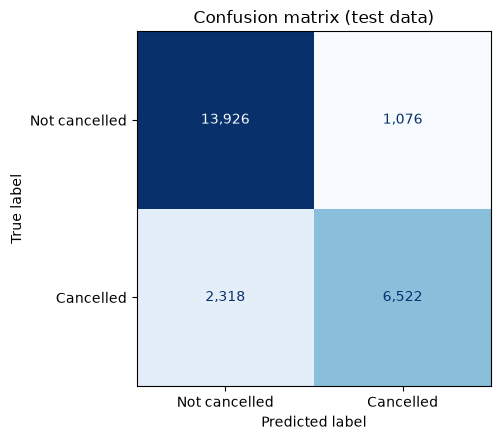

               precision    recall  f1-score   support

Not cancelled       0.86      0.93      0.89     15002
    Cancelled       0.86      0.74      0.79      8840

     accuracy                           0.86     23842
    macro avg       0.86      0.83      0.84     23842
 weighted avg       0.86      0.86      0.86     23842



In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Not cancelled", "Cancelled"],
    cmap="Blues", values_format=",", colorbar=False, ax=ax
)
ax.set_title("Confusion matrix (test data)")
plt.tight_layout()
plt.savefig("../images/09_confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_test, y_pred, target_names=["Not cancelled", "Cancelled"]))

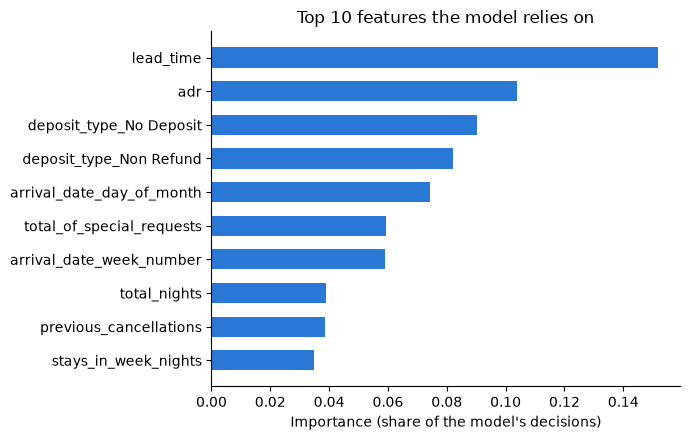

In [6]:
importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
top10 = importance.head(10).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top10.index, top10.values, color="#2a78d6", height=0.6)
ax.set_title("Top 10 features the model relies on")
ax.set_xlabel("Importance (share of the model's decisions)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../images/10_feature_importance.png", dpi=150)
plt.show()

In [7]:
results = df.loc[X_test.index, ["hotel", "arrival_date_month", "lead_time", "deposit_type",
                                "market_segment", "adr", "total_nights", "is_canceled"]].copy()
results["cancel_probability"] = model.predict_proba(X_test)[:, 1].round(3)
results["risk_level"] = pd.cut(results["cancel_probability"],
                               bins=[-0.01, 0.3, 0.7, 1.0], labels=["Low", "Medium", "High"])
results.to_csv("../data/predictions.csv", index=False)

print(results["risk_level"].value_counts().sort_index())
print(results.groupby("risk_level", observed=True)["is_canceled"].mean() * 100)

risk_level
Low       13562
Medium     4516
High       5764
Name: count, dtype: int64
risk_level
Low        9.570860
Medium    46.944198
High      94.066620
Name: is_canceled, dtype: float64


## Model summary
**Model:** Random Forest (100 trees), 80/20 train/test split, 24 features (64 after one-hot encoding)

| Metric | Score |
|---|---|
| Baseline (always "not cancelled") | 62.9% |
| **Accuracy** | **85.8%** |
| Precision (cancelled) | 0.86 |
| Recall (cancelled) | 0.74 |

**Top features:** lead time, price per night (adr), deposit type, special requests.

**Risk levels work:** High-risk bookings really cancelled 94.1% of the time; Low-risk only 9.6%.

**Limitations:**
- 32k identical rows may appear in both train and test sets, which could make the score slightly optimistic.
- Features were limited to information known at booking time (parking, assigned room and country were excluded as leakage risks).